# Musterlösung: Phasenfarben, Signalanteile und B₀-Karte

Diese Musterlösung folgt der Aufgabenfassung `experiment.ipynb`. Alle fünf Rechenaufgaben und die Kurzantworten sind ausgefüllt; zusätzliche Kommentare erklären Rechenschritte und Einheiten.

Verwendet werden die mitgelieferten Dual- und Triple-Echo-Daten der Wasser-/Ölflasche. Für den chemischen Frequenzabstand gilt die Skriptannahme von **3,5 ppm**, weil hier keine eigene Spektralmessung vorliegt. Echozeiten und Scannerfrequenz stammen aus den DICOM-Metadaten. Alle Abbildungen und Ergebnisse stehen direkt in den Zellenausgaben.

## Vorbereitung

Führen Sie bei Bedarf die Installationszelle aus und starten Sie danach den Kernel neu. Sind die Bibliotheken bereits installiert, beginnen Sie direkt mit der Importzelle.

In [ ]:
%pip install -r requirements-jupyterhub.txt

In [2]:
import numpy as np          # Rechnen mit ganzen Bildern (Arrays)
import mrt_hilfen as mh     # Laden, Prüfen und Anzeigen der DICOM-Bilder

print("Bibliotheken geladen.")

Bibliotheken geladen.


## Daten laden

Die Bilder werden mit **festen Dateinamen** aus dem Datenordner geladen. Jede Datei enthält ein Bild; die Echos sind nach aufsteigender Echozeit nummeriert:

| Aufnahme | Dateien |
| --- | --- |
| Dual-Echo | `<PRAEFIX>_dual_echo1_magnitude.dcm`, `…_dual_echo1_phase.dcm`, `…_dual_echo2_magnitude.dcm`, `…_dual_echo2_phase.dcm` |
| Triple-Echo | `<PRAEFIX>_triple_echo1_magnitude.dcm` … `<PRAEFIX>_triple_echo3_phase.dcm` |

Voreingestellt sind die Beispieldaten der Wasser-/Ölflasche. Für das Knee-Phantom oder Ihre eigenen Messdaten ändern Sie nur `DATENORDNER` und `PRAEFIX` (siehe Abschnitt „Eigene Messdaten“ am Ende). Die Hilfsdatei prüft, dass alle Bilder zur selben Aufnahme und Schichtebene gehören, und rechnet Phasen in Radiant um.

In [3]:
DATENORDNER = "daten/beispiel"
PRAEFIX = "wasser_oel"          # Alternativen: "wasser_oel_mit_knopf"; Knee-Phantom: "daten/knee" und "knee"

# dual.magnitude[k]: Magnitudenbild Echo k+1 [a.u., Signalwerte ohne physikalische Einheit]
# dual.phase[k]:     Phasenbild Echo k+1 [rad], Wertebereich -pi bis pi
# dual.te_ms[k]:     Echozeit Echo k+1 [ms]
# dual.f0_mhz:       Scannerfrequenz [MHz]
dual = mh.lade_echos(DATENORDNER, PRAEFIX, "dual_echo", 2)
triple = mh.lade_echos(DATENORDNER, PRAEFIX, "triple_echo", 3)   # gleiche Felder, 3 Echos

T1W_FFE dual echo | 2 Echos | TE = 6.901 / 13.8 ms | 512 × 512 Pixel | Ordner daten/beispiel
T1W_FFE triple echo | 3 Echos | TE = 9.201 / 16.101 / 23.001 ms | 512 × 512 Pixel | Ordner daten/beispiel


### Eingangsbilder der Dual-Echo-Aufnahme

Oben die Magnituden mit gemeinsamer Grauwertskala, unten die Phasen von −π bis π. Helligkeit ist keine Wasser-/Fett-Kennzeichnung; die Phase im signalarmen Hintergrund ist Rauschen.

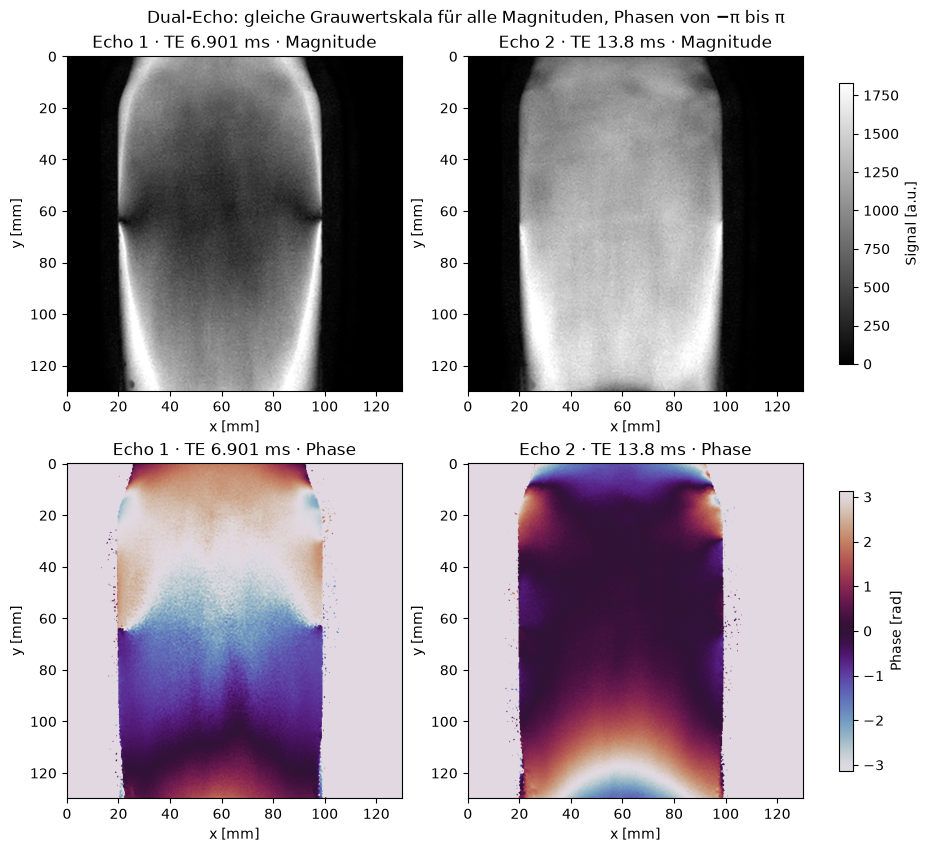

In [4]:
fig_dual = mh.eingangsbilder(dual, "Dual-Echo")

## Physikalische Grundlage: Wie weit dreht sich das Fettsignal gegenüber dem Wassersignal?

Stellen Sie sich Wasser- und Fettsignal wie im Versuchsskript (Abschnitt 3.2) als **zwei Zeiger** vor, die sich nach der Anregung drehen. Beide starten in dieselbe Richtung. Der Fett-Zeiger dreht sich aber etwas langsamer: Er fällt pro Sekunde um $\Delta f_\mathrm{cs}$ volle Runden hinter den Wasser-Zeiger zurück. Bis zur Echozeit TE ist so ein Winkel zwischen beiden Zeigern entstanden, die **Phasenverschiebung**

$$\varphi_\mathrm{cs}=360^\circ\cdot\Delta f_\mathrm{cs}\cdot TE .$$

Für Wasser und Fett zählt nur, wohin die Zeiger am Ende zeigen. Volle Runden von 360° spielen keine Rolle; entscheidend ist der **Restwinkel** nach Abzug aller vollen Runden:

| Restwinkel | Zeiger | Bezeichnung | Summensignal |
| --- | --- | --- | --- |
| ≈ 0° (also 360°, 720°, …) | zeigen in dieselbe Richtung | In-Phase (**IP**) | $W+F$, maximal |
| ≈ 180° (also 180°, 540°, …) | zeigen in entgegengesetzte Richtungen | Out-of-Phase (**OP**) | $\lvert W-F\rvert$, minimal |

**Beispiel:** Bei $\Delta f_\mathrm{cs}=224\,\mathrm{Hz}$ und $TE=6{,}9\,\mathrm{ms}=0{,}0069\,\mathrm{s}$ ist $\varphi_\mathrm{cs}=360^\circ\cdot 224\cdot 0{,}0069\approx 556^\circ$. Nach Abzug einer vollen Runde bleiben $196^\circ$: Das Echo ist fast OP.

**IP bedeutet also nicht „nur Wasser“**, sondern dass sich Wasser und Fett addieren.

### Aufgabe 1: Phasenverschiebung berechnen

Berechnen Sie den Frequenzabstand aus der Skriptannahme $\Delta f_\mathrm{cs}=3{,}5\,\mathrm{ppm}\cdot F_0$ (ppm × MHz ergibt Hz) oder setzen Sie Ihren im Spektrum gemessenen Wert in Hz ein. Berechnen Sie dann die Phasenverschiebung beider Echos in Grad. **Achtung Einheiten:** Die Echozeit liegt in Millisekunden vor; Hz × ms ergibt erst nach Division durch 1000 eine Zahl ohne Einheit.

In [5]:
F0 = dual.f0_mhz        # Scannerfrequenz [MHz], aus DICOM
TE_1 = dual.te_ms[0]    # Echozeit Echo 1 [ms]
TE_2 = dual.te_ms[1]    # Echozeit Echo 2 [ms]

# 3,5 ppm ist die Skriptannahme; ein gemessener Peakabstand in Hz würde chemie_hz direkt ersetzen.
chemie_hz = 3.5 * F0                               # [ppm] × [MHz] = [Hz]
# 360° pro voller Runde × Runden pro Sekunde [Hz = 1/s] × Zeit [s]; ms / 1000 = s
phase_cs_1_grad = 360 * chemie_hz * TE_1 / 1000    # [°]
phase_cs_2_grad = 360 * chemie_hz * TE_2 / 1000    # [°]

print("Frequenzabstand [Hz]:", chemie_hz)
print("Phasenverschiebung Echo 1 / Echo 2 [°]:", phase_cs_1_grad, phase_cs_2_grad)

Frequenzabstand [Hz]: 223.61361399999998
Phasenverschiebung Echo 1 / Echo 2 [°]: 555.53671807704 1110.912434352


Die folgende vorbereitete Zelle zieht von Ihren Phasenverschiebungen alle vollen Runden ab und ordnet zu: Das Echo mit einem Restwinkel nahe 0° ist IP, das andere OP. Außerdem wird eine **Signalmaske** berechnet. Sie enthält nur Pixel, in denen beide Echos genug Signal haben (15 % des 99. Perzentils). Außerhalb der Maske stehen in `ip_signal` und `op_signal` `NaN`-Werte, also „kein auswertbarer Zahlenwert“.

In [6]:
# ip, op [a.u.]; phase_ip, phase_op [rad]
ip, op, phase_ip, phase_op, meta_ip, meta_op = mh.ip_op_zuordnen(dual, phase_cs_1_grad, phase_cs_2_grad)

# maske, signal_ip: True/False je Pixel [ohne Einheit]
maske, signal_ip = mh.signalmaske(ip, op, phase_ip, phase_op)
ip_signal = np.where(maske, ip, np.nan)    # IP-Magnitude, nur gültige Pixel [a.u.]
op_signal = np.where(maske, op, np.nan)    # OP-Magnitude, nur gültige Pixel [a.u.]
signalgrenze = mh.fenster(ip, op)[1]       # Anzeigegrenze der Magnituden [a.u.]

Echo 2: TE 13.8 ms, Phasenverschiebung 1111° = 3 volle Runde(n) + 31° → IP (Restwinkel nahe 0°)
Echo 1: TE 6.901 ms, Phasenverschiebung 556° = 1 volle Runde(n) + 196° → OP (Restwinkel nahe 180°)
Auswertbare Pixel: 153169 von 262144


## Phase als Farbe, Magnitude als Helligkeit

### Aufgabe 2: Die relative Phase berechnen

Ziehen Sie die IP-Phase von der OP-Phase ab. Winkel wiederholen sich nach $2\pi$; führen Sie die Differenz deshalb auf den Bereich von $-\pi$ bis $\pi$ zurück:

$$\Delta\phi=\arg\{\exp[i(\phi_\mathrm{OP}-\phi_\mathrm{IP})]\}.$$

**Python-Hilfe:** `np.angle(z)` liefert den Winkel einer komplexen Zahl, `np.exp(...)` die Exponentialfunktion, `1j` ist die imaginäre Einheit.

In [7]:
# exp(i·Winkel) „vergisst“ volle Runden; np.angle liefert dann einen Wert in [-pi, pi].
delta_phase = np.angle(np.exp(1j * (phase_op - phase_ip)))   # [rad]

### Aufgabe 3: Farbe und Helligkeit zusammensetzen

Berechnen Sie zwei **Farbgewichte** $r=(1-\cos\Delta\phi)/2$ und $b=1-r$: Bei gleicher Phase wird das Bild blau, bei entgegengesetzter Phase rot. Die Helligkeit $h$ ist die IP-Magnitude geteilt durch `signalgrenze`, begrenzt mit `np.clip(..., 0, 1)`. Die Farbkanäle sind

$$\mathrm{RGB}=(h\,r,\;0,\;h\,b).$$

Das Zusammensetzen und Anzeigen des Bildes ist vorbereitet.

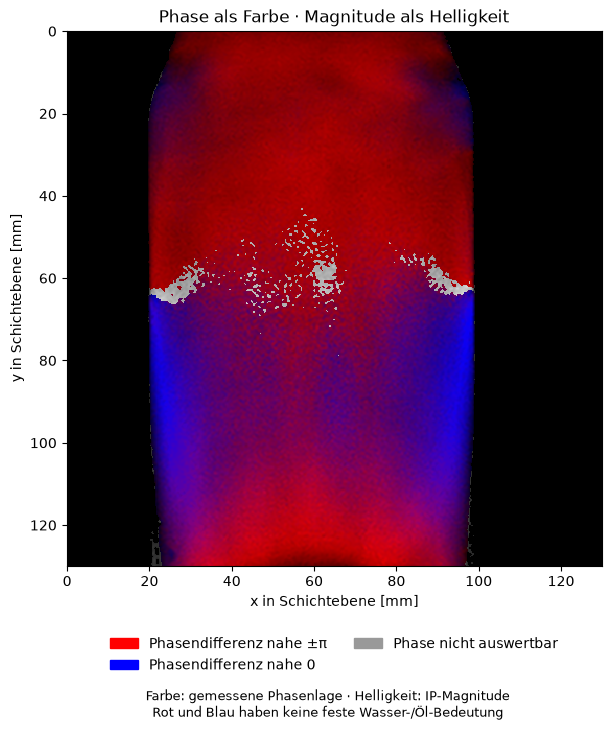

In [8]:
# cos(0) = 1 → r = 0 (blau); cos(±pi) = -1 → r = 1 (rot).
gewicht_rot = (1 - np.cos(delta_phase)) / 2       # [ohne Einheit, 0 bis 1]
gewicht_blau = 1 - gewicht_rot                     # [ohne Einheit, 0 bis 1]
# Nur die Anzeigehelligkeit wird begrenzt; ip selbst bleibt unverändert.
helligkeit = np.clip(ip / signalgrenze, 0, 1)      # [a.u.] / [a.u.] → ohne Einheit, 0 bis 1
rot = helligkeit * gewicht_rot                     # [ohne Einheit, 0 bis 1]
blau = helligkeit * gewicht_blau                   # [ohne Einheit, 0 bis 1]

rgb = mh.farbbild_anzeigen(rot, blau, helligkeit, maske, signal_ip, meta_ip)

### So lesen Sie das Farbbild

| Farbe | Aussage |
| --- | --- |
| Blau | Die gemessene OP-/IP-Phasendifferenz liegt nahe null. |
| Rot | Die Phasendifferenz liegt nahe ±π. |
| Violett | Die Phase liegt dazwischen. |
| Grau | IP-Signal ist vorhanden, die Phase ist hier nicht auswertbar. |
| Schwarz | Zu wenig IP-Signal. |

Die Farben zeigen Phasenunterschiede, **keine eindeutige Wasser-/Öl-Verteilung**. Feldabweichungen und echoabhängige Phasenfehler beeinflussen sie ebenfalls.

## Größeren und kleineren Signalanteil pro Pixel berechnen

### Aufgabe 4: Die Magnituden auswerten

Aus dem vereinfachten Magnitudenmodell folgen ein größerer Anteil $A$, ein kleinerer Anteil $B$ und der relative Anteil von $B$:

$$A=\frac{M_\mathrm{IP}+M_\mathrm{OP}}{2},\qquad
B=\frac{M_\mathrm{IP}-M_\mathrm{OP}}{2},\qquad
p_B=100\,\frac{B}{A+B}.$$

Rechnen Sie mit `ip_signal` und `op_signal`; die Formeln gelten dann für jedes gültige Pixel gleichzeitig. **A ist nicht automatisch Wasser und B nicht automatisch Fett.** Im idealen Modell liegt $p_B$ zwischen 0 und 50 %. Werte außerhalb zeigen Grenzen des Modells; verwenden Sie keinen Betrag und kein Abschneiden.

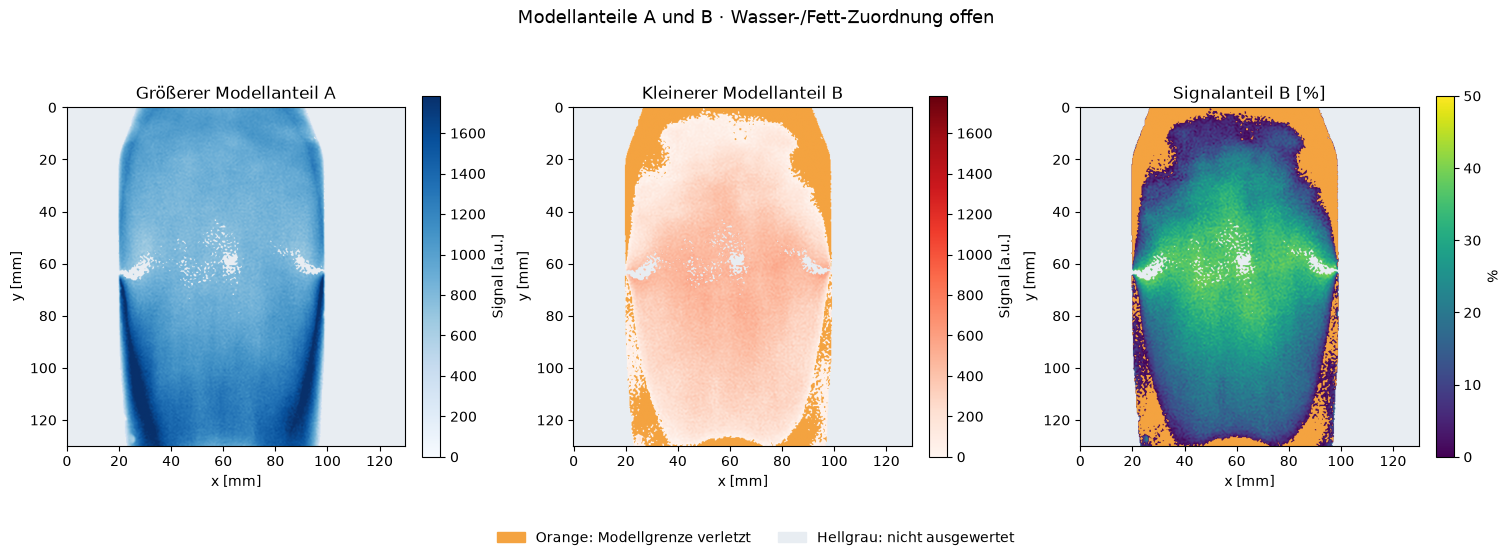

In [9]:
# A + B ergibt wieder IP, A - B wieder OP.
anteil_a = (ip_signal + op_signal) / 2                             # [a.u.]
anteil_b = (ip_signal - op_signal) / 2                             # [a.u.]
# B relativ zur Summe A + B (= IP); im idealen Modell 0 bis 50 %.
signalanteil_b_prozent = 100 * anteil_b / (anteil_a + anteil_b)    # [a.u.] / [a.u.] × 100 → [%]

fig_anteile = mh.signalanteile_anzeigen(anteil_a, anteil_b, signalanteil_b_prozent, maske, meta_ip)

### Ergebnisse prüfen

**Orange** markiert negative Signale oder Prozentwerte außerhalb von 0 bis 50 %, **Hellgrau** nicht ausgewertete Pixel. Die folgende Kontrollzelle prüft Ihre Formeln aus Aufgabe 2 bis 4 und zählt Pixel mit einer Modellverletzung.

In [10]:
assert delta_phase.shape == ip.shape and np.all(np.abs(delta_phase) <= np.pi + 1e-12)
assert np.isfinite(rgb).all() and np.all((rgb >= 0) & (rgb <= 1))
np.testing.assert_allclose((gewicht_rot + gewicht_blau)[maske], 1)
np.testing.assert_allclose((anteil_a + anteil_b)[maske], ip[maske])
np.testing.assert_allclose((anteil_a - anteil_b)[maske], op[maske])
assert np.isnan(signalanteil_b_prozent[~maske]).all()

modellverletzung = maske & ((anteil_a < 0) | (anteil_b < 0))   # True/False je Pixel
print("Kontrollen erfolgreich.")
print("Gültige Pixel:", int(maske.sum()))
print("Davon mit Modellverletzung [%]:", round(100 * modellverletzung.sum() / maske.sum(), 2))

Kontrollen erfolgreich.
Gültige Pixel: 153169
Davon mit Modellverletzung [%]: 16.53


### Kurzantworten der Musterlösung

1. **IP enthält beide Signalbeiträge.** Wasser und Fett addieren sich näherungsweise gleichphasig. Deshalb kann auch ein reiner Ölbereich eine hohe IP-Magnitude haben.
2. **Das Farbgewicht beschreibt nur die Phasenlage.** `gewicht_rot` wird aus der gemessenen Phasendifferenz berechnet und steuert den Rotkanal. `signalanteil_b_prozent` wird dagegen aus beiden Magnituden berechnet und beschreibt den kleineren Modellbeitrag relativ zu A + B.
3. **Die Zuordnung bleibt offen.** Die Mischungen W = 80, F = 20 und W = 20, F = 80 liefern im Idealmodell beide IP = 100 und OP = 60, also A = 80 und B = 20. A kann deshalb Wasser oder Fett sein. Die Phasenfarben hängen auch von Feldabweichungen und Phasenfehlern ab und legen die Stoffzuordnung nicht fest. Die Anteile sind keine validierten Konzentrationen oder Volumenanteile.

## B₀-Karte aus der Triple-Echo-Aufnahme

Wir vergleichen die Phasen von **Echo 3 und Echo 1**. Ist die chemische Phasenverschiebung zwischen beiden ein Vielfaches von 360° (Restwinkel ≈ 0°), stehen die Fett- und Wasser-Zeiger bei beiden Echos gleich zueinander. Die verbleibende Phasendifferenz entsteht dann durch lokale Feldabweichungen. Die vorbereitete Zelle zeigt die Eingangsbilder und berechnet diesen Restwinkel.

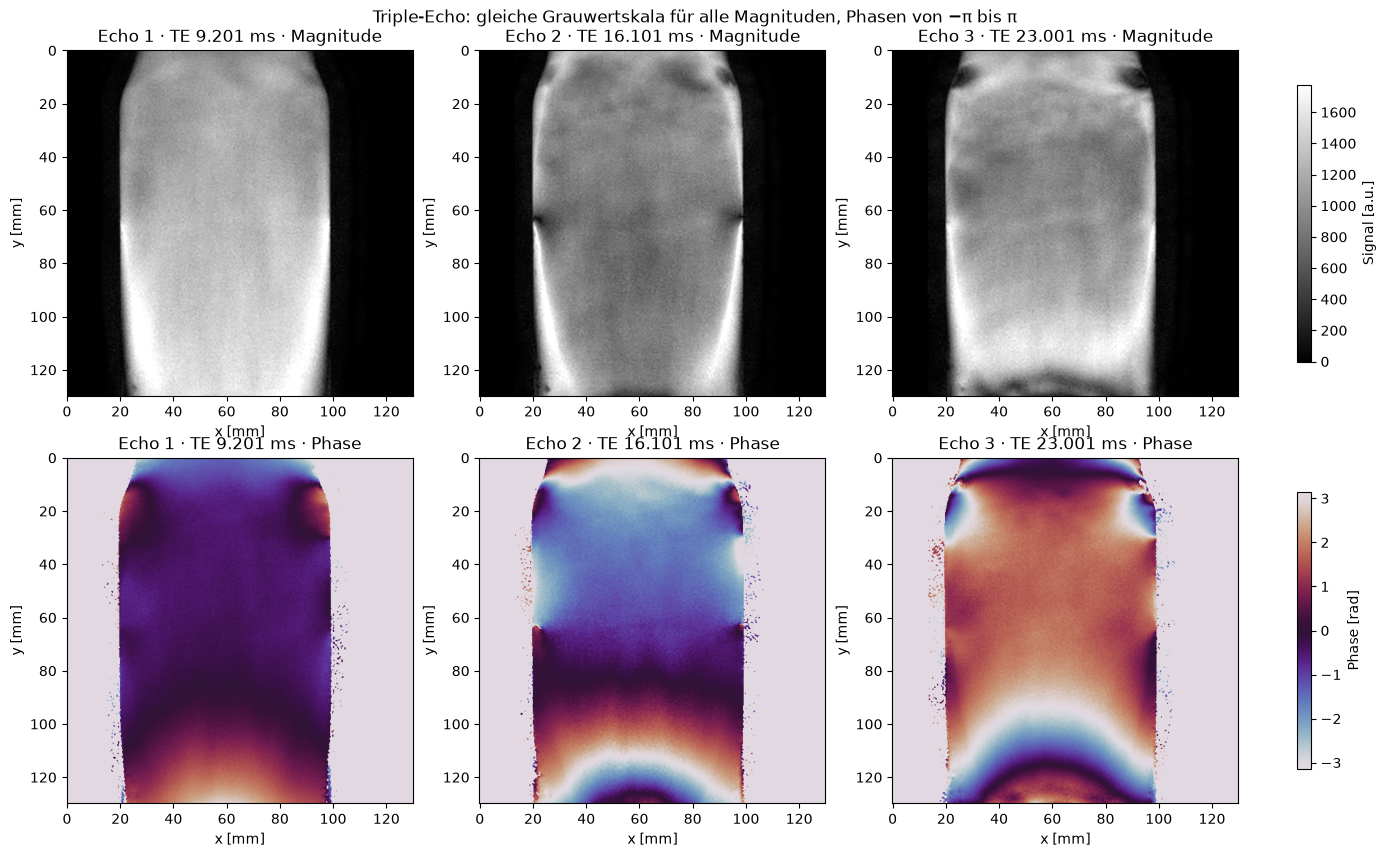

Chemische Phasenverschiebung zwischen Echo 1 und 3 [°]: 1110.9
Restwinkel nach vollen Runden [°] (ideal ≈ 0): 30.9


In [11]:
fig_triple = mh.eingangsbilder(triple, "Triple-Echo")

TE_B0_1 = triple.te_ms[0]      # Echozeit Echo 1 [ms]
TE_B0_3 = triple.te_ms[2]      # Echozeit Echo 3 [ms]
phase_1 = triple.phase[0]      # Phase Echo 1 [rad]
phase_3 = triple.phase[2]      # Phase Echo 3 [rad]
phase_cs_13_grad = 360 * chemie_hz * (TE_B0_3 - TE_B0_1) / 1000    # [°]
print("Chemische Phasenverschiebung zwischen Echo 1 und 3 [°]:", round(phase_cs_13_grad, 1))
print("Restwinkel nach vollen Runden [°] (ideal ≈ 0):", round((phase_cs_13_grad + 180) % 360 - 180, 1))

### Aufgabe 5: Phasendifferenz → Frequenzabweichung

Berechnen Sie den Echoabstand in **Sekunden**, die Phasendifferenz in **Radiant** und daraus die Frequenzabweichung in **Hz**:

$$\Delta TE=\frac{TE_3-TE_1}{1000},\qquad
\Delta\phi=\arg\{\exp[i(\phi_3-\phi_1)]\},\qquad
\Delta f=\frac{\Delta\phi}{2\pi\,\Delta TE}.$$

Die Karte wird für die ganze Schicht **ohne Maske und ohne räumliches Entfalten** gezeigt. Im signalarmen Hintergrund ist die Phase verrauscht. Ohne Entfalten ist die Frequenz nur im Bereich $\pm 1/(2\Delta TE)$ eindeutig; Sprünge können Phasenumbrüche sein.

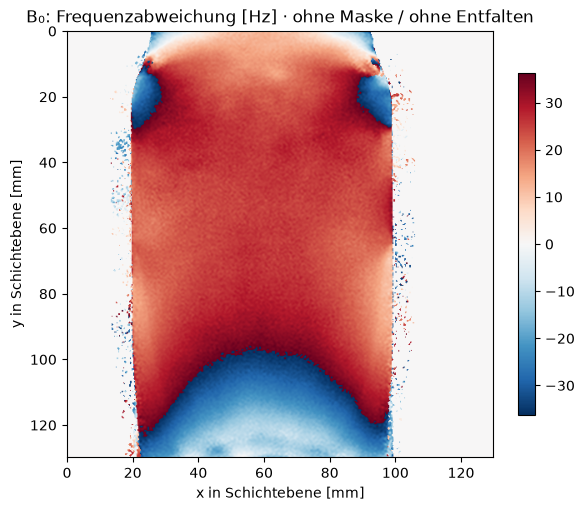

In [12]:
delta_te_b0_s = (TE_B0_3 - TE_B0_1) / 1000                     # [ms] / 1000 → [s]
# Echo 3 relativ zu Echo 1: Die absolute Startphase fällt heraus.
delta_phase_b0 = np.angle(np.exp(1j * (phase_3 - phase_1)))    # [rad]
# rad / (2·pi·s) = 1/s = Hz; F0 wird für die Frequenzabweichung nicht benötigt.
b0_hz = delta_phase_b0 / (2 * np.pi * delta_te_b0_s)           # [Hz]

fig_b0 = mh.b0_anzeigen(b0_hz, delta_te_b0_s, triple.meta[0])

## Eigene Messdaten verwenden

Benötigt werden nur **Einzelbilder einer Schicht**: die Bilder der Dual-Echo- und der Triple-Echo-Aufnahme, jeweils Magnitude und Phase je Echo, also zehn Bilddateien. So verwenden Sie Ihre Daten:

1. Laden Sie die exportierten DICOM-Dateien in den Ordner `daten/eigene/` hoch.
2. Führen Sie `mh.dateiliste("daten/eigene")` in einer neuen Zelle aus. Die Liste zeigt für jede Datei Aufnahme, Bildtyp und Echozeit.
3. Benennen Sie die zehn Dateien Ihrer gewählten Schicht nach dem festen Schema um, mit dem Präfix `eigene`: `eigene_dual_echo1_magnitude.dcm`, `eigene_dual_echo1_phase.dcm`, … bis `eigene_triple_echo3_phase.dcm`. Echo 1 ist jeweils das Echo mit der kürzesten Echozeit.
4. Setzen Sie in der Ladezelle `DATENORDNER = "daten/eigene"` und `PRAEFIX = "eigene"` und führen Sie alle Zellen erneut aus. Setzen Sie in Aufgabe 1 Ihren im Spektrum gemessenen Frequenzabstand ein.

### Hintergrund

Die Übung zeigt einen qualitativen Phasen-Magnitude-Blend und eine vereinfachte Signalaufteilung. Für eine belastbare komplexe Wasser-/Fett-Trennung müssen unter anderem räumliche Phasenfehler berücksichtigt werden: [Berglund et al., 2011: Two-point Dixon method with flexible echo times](https://doi.org/10.1002/mrm.22679). Die B₀-Frequenzkarte folgt dem Zusammenhang zwischen Phasendifferenz und Echoabstand: [SDCFlows-Dokumentation](https://www.nipreps.org/sdcflows/1.4/_modules/sdcflows/workflows/fit/fieldmap.html).

### Prüfung der Musterlösung

Die folgenden Kontrollen prüfen IP/OP-Zuordnung, Echozeiten und die B₀-Karte für die Beispieldaten.

In [13]:
assert dual.meta[0]["aufnahme"] == "T1W_FFE dual echo"
assert triple.meta[0]["aufnahme"] == "T1W_FFE triple echo"
assert ip.shape == op.shape == (512, 512)
# Beispieldaten: frühes Echo (6,9 ms) ist OP, spätes Echo (13,8 ms) ist IP.
assert meta_op["echozeit_ms"] == TE_1 and meta_ip["echozeit_ms"] == TE_2
# Restwinkel: IP nahe 0°, OP nahe 180° (Toleranz ±54° = 0,15 Runden).
assert abs((phase_cs_2_grad + 180) % 360 - 180) < 54
assert abs(phase_cs_1_grad % 360 - 180) < 54

assert delta_te_b0_s > 0 and b0_hz.shape == ip.shape
assert np.isfinite(b0_hz).all()
assert np.max(np.abs(b0_hz)) <= 1 / (2 * delta_te_b0_s) + 1e-10
np.testing.assert_allclose(b0_hz * (2 * np.pi * delta_te_b0_s), delta_phase_b0)
print("Alle Kontrollen der Musterlösung erfolgreich.")

Alle Kontrollen der Musterlösung erfolgreich.
